# Regularized logistic regression (Esther)

## 0. Importations

In [3]:
from helpers import *
from implementations import *
from preprocessing import *
from validation import *
import numpy as np
from pathlib import Path
from plots import *

## 1. Data loading & preprocessing

In [5]:
project_dir = Path.cwd()  # Updated to use Path.cwd()
data_dir = project_dir / "data"
output_dir = project_dir / "outputs"
output_dir.mkdir(exist_ok=True)

x_train, x_test, y_train, _, test_ids = load_csv_data(data_dir)
names = load_feature_names(data_dir)

In [6]:
tx_train, tx_test = clean_and_standardize(x_train, x_test, names, one_hot=True)
y01 = (y_train == 1).astype(float)   # {-1,1} -> {0,1} pour la régression logistique

## 2. Split train & validation set

In [7]:
'''tx_tr, tx_va, y_tr, y_va = split_train_validation(y_train, tx_train)   # labels en {-1, 1}
y_tr01 = (y_tr == 1).astype(float) '''
# split the RAW data first: 80% train / 20% validation (seed 1)
x_tr_raw, x_va_raw, y_tr, y_va = split_train_validation(y_train, x_train)   # labels in {-1, 1}

# preprocessing statistics computed on the training part only
tx_tr, tx_va = clean_and_standardize(x_tr_raw, x_va_raw, names, one_hot=True)
y_tr01 = (y_tr == 1).astype(float)

## 3. First training (verify the loss decrease)

In [8]:
max_iters, gamma = 500, 0.5
w0 = np.zeros(tx_tr.shape[1])   # was tx_train.shape[1]

w, loss = reg_logistic_regression(y_tr01, tx_tr, 1e-4, w0, max_iters, gamma)
print("loss train :", loss, "| loss validation :", logistic_loss((y_va == 1).astype(float), tx_va, w))

scores = tx_va @ w
t = best_threshold(y_va, scores)
f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
print(f"F1 validation = {f1:.3f} (seuil {t:.2f})")

loss train : 0.2225374329862245 | loss validation : 0.22358505499641865
F1 validation = 0.430 (seuil -1.34)


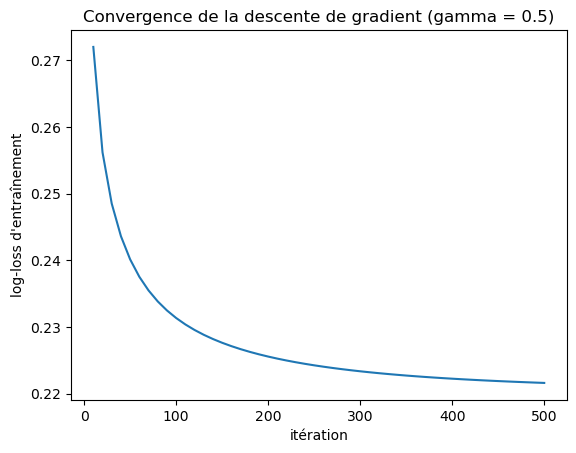

In [ ]:
# convergence curve on a 50,000-row subsample (faster, same shape)
plot_convergence(y_tr[:50000], tx_tr[:50000], lambda_=0, gamma=0.5, max_iters=500,
                 path=output_dir / "convergence.png")

## 4. Lambda tuning

4.1 Un seul split : entraînement sur 80 %, validation sur 20 %

In [10]:
results = []
for lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:
    w, _ = reg_logistic_regression(y_tr01, tx_tr, lambda_, w0, max_iters, gamma)
    scores = tx_va @ w
    t = best_threshold(y_va, scores)
    f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
    results.append((f1, lambda_, t))
    print(f"lambda = {lambda_:g}  ->  F1 = {f1:.3f}  (seuil {t:.2f})")

best_f1, best_lambda, best_t = max(results)
print("meilleur :", best_lambda, best_t, best_f1)

lambda = 0  ->  F1 = 0.430  (seuil -1.48)
lambda = 1e-05  ->  F1 = 0.430  (seuil -1.48)
lambda = 0.0001  ->  F1 = 0.430  (seuil -1.34)
lambda = 0.001  ->  F1 = 0.428  (seuil -1.48)
lambda = 0.01  ->  F1 = 0.399  (seuil -1.53)
meilleur : 0 -1.4819550309792069 0.4303088188475008


4.2 Cross validation sur 5 plis

In [11]:
from implementations import reg_logistic_regression  # à mettre en haut du fichier


def build_k_indices(n, k, seed=1):
    """Randomly split the indices 0..n-1 into k folds of (almost) equal size.

    Args:
        n: number of samples
        k: number of folds
        seed: random seed, so that the folds are the same at every run

    Returns:
        a list of k arrays of indices
    """
    rng = np.random.default_rng(seed)
    return np.array_split(rng.permutation(n), k)


def cross_validation(y, x_raw, names, lambda_, k=5, max_iters=500, gamma=0.5,
                     seed=1, one_hot=True):
    """k-fold CV; the preprocessing is fitted on the training folds only."""
    folds = build_k_indices(len(y), k, seed)
    f1s, thresholds = [], []
    for i in range(k):
        val = folds[i]
        tr = np.concatenate([folds[j] for j in range(k) if j != i])
        tx_tr_f, tx_val_f = clean_and_standardize(x_raw[tr], x_raw[val], names, one_hot=one_hot)

        w0 = np.zeros(tx_tr_f.shape[1])
        w, _ = reg_logistic_regression((y[tr] == 1).astype(float), tx_tr_f, lambda_,
                                       w0, max_iters, gamma)
        scores = tx_val_f @ w
        t = best_threshold(y[val], scores)
        f1s.append(f1_score(y[val], np.where(scores >= t, 1, -1)))
        thresholds.append(t)
    return np.array(f1s), np.array(thresholds)

In [12]:
'''
results = []
for lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:
    f1s, ts = cross_validation(y_train, x_train, names, lambda_, max_iters=max_iters, gamma=gamma)
    results.append((f1s.mean(), f1s.std(), lambda_, ts.mean()))
    print(f"lambda = {lambda_:g}  ->  F1 = {f1s.mean():.3f} ± {f1s.std():.3f}  (seuil {ts.mean():.2f})")

best_f1, _, best_lambda, best_t = max(results)
print("meilleur :", best_lambda, best_t, best_f1)
'''

'\nresults = []\nfor lambda_ in [0, 1e-5, 1e-4, 1e-3, 1e-2]:\n    f1s, ts = cross_validation(y_train, x_train, names, lambda_, max_iters=max_iters, gamma=gamma)\n    results.append((f1s.mean(), f1s.std(), lambda_, ts.mean()))\n    print(f"lambda = {lambda_:g}  ->  F1 = {f1s.mean():.3f} ± {f1s.std():.3f}  (seuil {ts.mean():.2f})")\n\nbest_f1, _, best_lambda, best_t = max(results)\nprint("meilleur :", best_lambda, best_t, best_f1)\n'

In [13]:
'''plot_cv_lambda(results, path=output_dir / "cv_lambda.png")'''


'plot_cv_lambda(results, path=output_dir / "cv_lambda.png")'

4.3 Analyse du modèle choisi

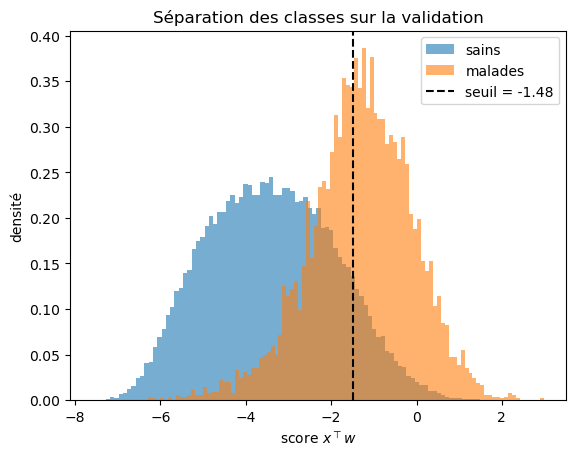

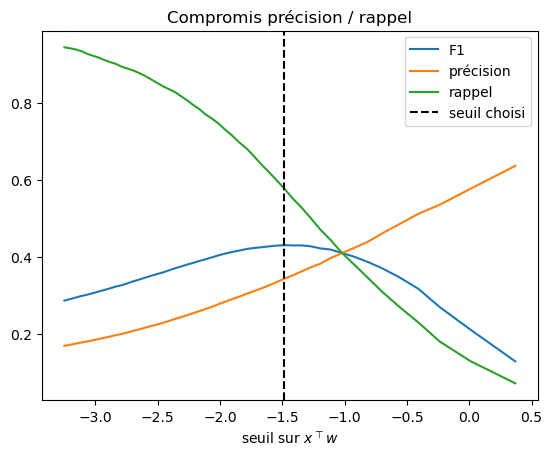

In [14]:
# model trained on the split with the chosen lambda, evaluated on the validation part
w, _ = reg_logistic_regression((y_tr == 1).astype(float), tx_tr, best_lambda,
                               np.zeros(tx_tr.shape[1]), 500, 0.5)
scores = tx_va @ w

plot_score_distribution(y_va, scores, best_t)
plot_threshold_curves(y_va, scores, best_t)

Les scores des deux classes sont décalés mais se chevauchent largement, ce qui limite la performance atteignable par un classifieur linéaire. Le seuil qui maximise le F1 (−1.6, soit une probabilité ≈ 0.17) donne un rappel de 0.60 pour une précision de 0.31; le maximum du F1 étant plat, ce choix est peu sensible à la valeur exacte du seuil.

## 5. Final training & Submission

In [15]:
'''w, loss = reg_logistic_regression(y01, tx_train, best_lambda, w0, max_iters, gamma)
print("loss train :", loss, "| loss validation :", logistic_loss((y_va == 1).astype(float), tx_va, w))

scores = tx_va @ w
t = best_threshold(y_va, scores)
f1 = f1_score(y_va, np.where(scores >= t, 1, -1))
print(f"F1 validation = {f1:.3f} (seuil {t:.2f})")
print(t)
'''

# final preprocessing: fitted on ALL the training data, applied to the test data
tx_train, tx_test = clean_and_standardize(x_train, x_test, names, one_hot=True)
y01 = (y_train == 1).astype(float)

w0 = np.zeros(tx_train.shape[1])
w, loss = reg_logistic_regression(y01, tx_train, best_lambda, w0, max_iters, gamma)
print("loss train :", loss)

loss train : 0.22256844998828465


Résultats: 

4.1 Un seul split : entraînement sur 80 %, validation sur 20 %

    loss train : 0.22771585642698902 | loss validation : 0.22819828457209074 
      
            F1 validation = 0.418 (seuil -1.46)

4.2 Cross validation sur 5 plis

    loss train : 0.23188015843203327 | loss validation : 0.23239870804220816
      
            F1 validation = 0.404 (seuil -1.52)

4.1 Un seul split : entraînement sur 80 %, validation sur 20 % + one hot preprocessing :

    loss train : 0.22256844998828465 | loss validation : 0.22299282188495165

            F1 validation = 0.432 (seuil -1.48)

4.2 Cross validation sur 5 plis + one hot preprocessing

    loss train : 0.22256844998828465 | loss validation : 0.22299282188495165

        F1 validation = 0.432 (seuil -1.48)

In [16]:
y_pred = np.where(tx_test @ w >= best_t, 1, -1)
create_csv_submission(test_ids, y_pred, output_dir / "submission_reg_logistic_cv_one_hot_split_before.csv")
print("prédits positifs :", (y_pred == 1).mean())

prédits positifs : 0.14905969153128115


In [17]:
sub = np.genfromtxt(output_dir / "submission_reg_logistic_cv_one_hot_split_before.csv", delimiter=",", names=True)

print(open(output_dir / "submission_reg_logistic_cv_one_hot_split_before.csv").readlines()[:3])


['Id,Prediction\n', '328135,-1\n', '328136,-1\n']


## 6. Results

In [19]:
ONE_HOT = True   # False: same preprocessing as the linear baselines / True: final preprocessing

# 1) split the RAW data first: 80% train / 20% validation (seed 1)
x_tr_raw, x_va_raw, y_tr, y_va = split_train_validation(y_train, x_train, ratio=0.8, seed=1)

# 2) preprocessing statistics computed on the 80% training part only,
#    then applied unchanged to the validation part
tx_tr, tx_va = clean_and_standardize(x_tr_raw, x_va_raw, names, one_hot=ONE_HOT)

# 3) validation part cut in two halves: calibration / evaluation (seed 2)
tx_cal, tx_ev, y_cal, y_ev = split_train_validation(y_va, tx_va, ratio=0.5, seed=2)
print(f"train {len(y_tr)} | calibration {len(y_cal)} | evaluation {len(y_ev)}")


def metrics(y, pred):
    """F1, precision, recall, accuracy; labels in {-1, 1}."""
    tp = np.sum((pred == 1) & (y == 1))
    return (f1_score(y, pred), tp / max(np.sum(pred == 1), 1),
            tp / np.sum(y == 1), np.mean(pred == y))


def latex_row(name, thr, m):
    return f"{name} & {thr} & " + " & ".join(f"{v:.4f}".lstrip("0") for v in m) + r" \\"


def report(name, w, t):
    """Print the Zero and calibrated rows, evaluated on the evaluation set."""
    scores = tx_ev @ w
    print(latex_row(name, "Zero", metrics(y_ev, np.where(scores >= 0, 1, -1))))
    print(latex_row(name, "Cal.", metrics(y_ev, np.where(scores >= t, 1, -1))))


y_tr01 = (y_tr == 1).astype(float)
w0 = np.zeros(tx_tr.shape[1])

# 4) Logistic: threshold chosen on calibration, metrics on evaluation
w, _ = logistic_regression(y_tr01, tx_tr, w0, 500, 0.5)
t = best_threshold(y_cal, tx_cal @ w)
print(f"Logistic: threshold = {t:.4f}")
report("Logistic", w, t)

# 5) Reg. logistic: (lambda, threshold) pair chosen on calibration
best = None
for lambda_ in [1e-5, 1e-4, 1e-3, 1e-2]:
    w, _ = reg_logistic_regression(y_tr01, tx_tr, lambda_, w0, 500, 0.5)
    t = best_threshold(y_cal, tx_cal @ w)
    f1 = f1_score(y_cal, np.where(tx_cal @ w >= t, 1, -1))
    print(f"  lambda = {lambda_:g}: calibration F1 = {f1:.4f}")
    if best is None or f1 > best[0]:
        best = (f1, lambda_, t, w)

_, lam, t, w = best
print(f"Reg. logistic: lambda = {lam:g}, threshold = {t:.4f}")
report("Reg. logistic", w, t)

train 262508 | calibration 32813 | evaluation 32814
Logistic: threshold = -1.4987
Logistic & Zero & .2093 & .5802 & .1276 & .9125 \\
Logistic & Cal. & .4337 & .3437 & .5875 & .8608 \\
  lambda = 1e-05: calibration F1 = 0.4269
  lambda = 0.0001: calibration F1 = 0.4261
  lambda = 0.001: calibration F1 = 0.4240
  lambda = 0.01: calibration F1 = 0.3958
Reg. logistic: lambda = 1e-05, threshold = -1.4979
Reg. logistic & Zero & .2093 & .5802 & .1276 & .9125 \\
Reg. logistic & Cal. & .4336 & .3438 & .5868 & .8609 \\


onehot = true :
    train 262508 | calibration 32813 | evaluation 32814

    Logistic: threshold = -1.4986

    Logistic & Zero & .2093 & .5802 & .1276 & .9125 \\

    Logistic & Cal. & .4337 & .3437 & .5875 & .8608 \\

    lambda = 1e-05: calibration F1 = 0.4269

    lambda = 0.0001: calibration F1 = 0.4261

    lambda = 0.001: calibration F1 = 0.4240

    lambda = 0.01: calibration F1 = 0.3961

    Reg. logistic: lambda = 1e-05, threshold = -1.4980

    Reg. logistic & Zero & .2093 & .5802 & .1276 & .9125 \\
    
    Reg. logistic & Cal. & .4337 & .3439 & .5872 & .8609 \\


